# Correlation Network (Minimum Spanning Tree)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Turns a correlation matrix of many assets into a tree. Each correlation becomes a distance d = √(2(1 − ρ)), and the minimum spanning tree keeps only the strongest links that connect every asset (Mantegna 1999). A 600-cell heatmap becomes a readable map of which stocks move together, which clusters exist, and which names sit at the centre of the market.

## When to use

- Find clusters and "hub" stocks in a universe of 20–200 assets
- Check whether sector labels match how stocks actually trade
- Explain portfolio concentration (many holdings on one branch = one bet)

## Avoid when

- There are fewer than ~10 assets (a correlation heatmap is clearer)
- Readers need exact correlation values (the tree drops most pairs)
- The return window is short or crosses a regime change (the tree is unstable)

## Alternatives

- Clustered correlation heatmap (HRP dendrogram)
- Correlation heatmap

## Design tips

- Use returns, not prices, and state the window length
- Color nodes by sector (four colors or fewer) to test whether clusters match labels
- Scale edge width by correlation so the strongest links stand out
- Re-run on sub-periods; a stable tree is more trustworthy

## Example

Simulated daily returns for 24 stocks in four sectors over two years (market factor + sector factor + stock-specific noise). Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import networkx as nx

### Data

In [2]:
rng = np.random.default_rng(21)
sectors = {"Tech": 7, "Financials": 6, "Energy": 5, "Healthcare": 6}
tickers, sector_of = [], {}
for s, k in sectors.items():
    for i in range(k):
        t = f"{s[:3].upper()}{i + 1}"
        tickers.append(t)
        sector_of[t] = s
n_days = 504
market = rng.normal(0.0004, 0.010, n_days)
sector_f = {s: rng.normal(0, 0.008, n_days) for s in sectors}
rets = pd.DataFrame({
    t: rng.uniform(0.6, 1.3) * market + rng.uniform(0.6, 1.2) * sector_f[sector_of[t]]
       + rng.normal(0, 0.009, n_days)
    for t in tickers})
corr = rets.corr()
corr.round(2).iloc[:5, :5]

,TEC1,TEC2,TEC3,TEC4,TEC5
TEC1,1.00,0.65,0.51,0.63,0.59
TEC2,0.65,1.00,0.55,0.70,0.61
TEC3,0.51,0.55,1.00,0.60,0.58
TEC4,0.63,0.70,0.60,1.00,0.66
TEC5,0.59,0.61,0.58,0.66,1.00


### Plot

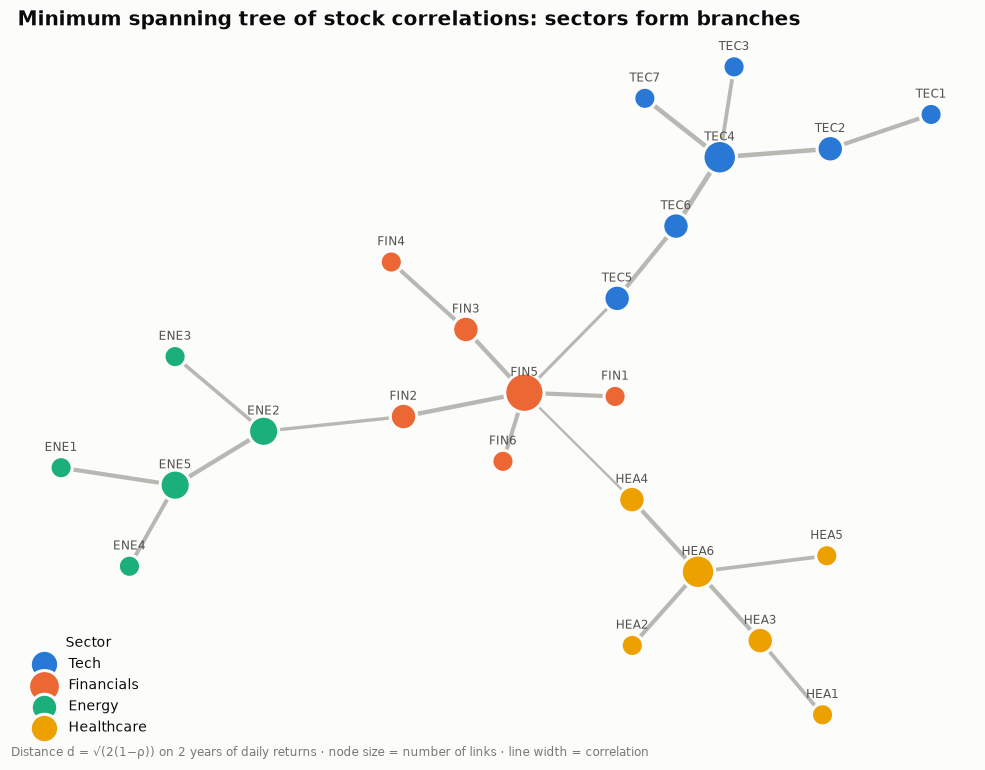

In [3]:
dist = np.sqrt(2 * (1 - corr))
G = nx.Graph()
for i, a in enumerate(tickers):
    for b in tickers[i + 1:]:
        G.add_edge(a, b, weight=dist.loc[a, b], corr=corr.loc[a, b])
mst = nx.minimum_spanning_tree(G, weight="weight")
pos = nx.kamada_kawai_layout(mst, weight="weight")

fig, ax = plt.subplots(figsize=(9, 7))
for a, b, d in mst.edges(data=True):
    (x1, y1), (x2, y2) = pos[a], pos[b]
    ax.plot([x1, x2], [y1, y2], color="#b8b7b1", linewidth=0.5 + 5 * max(d["corr"] - 0.2, 0), zorder=1)
for k, s in enumerate(sectors):
    nodes = [t for t in mst.nodes if sector_of[t] == s]
    xy = np.array([pos[t] for t in nodes])
    deg = np.array([mst.degree(t) for t in nodes])
    ax.scatter(xy[:, 0], xy[:, 1], s=120 + 90 * deg, color=PALETTE[k], edgecolor="#fcfcfb",
               linewidth=2, zorder=3, label=s)
for t, (x, y) in pos.items():
    ax.annotate(t, (x, y), xytext=(0, 11), textcoords="offset points", ha="center", fontsize=8,
                color="#52514e", zorder=4)
ax.set_axis_off()
ax.set_title("Minimum spanning tree of stock correlations: sectors form branches")
ax.legend(loc="lower left", title="Sector", fontsize=9, title_fontsize=9)
fig.text(0.01, 0.01, "Distance d = √(2(1−ρ)) on 2 years of daily returns · node size = number of links · "
         "line width = correlation", fontsize=8, color="#7a7974")
fig.tight_layout()
plt.show()

## How to read it

Each dot is a stock, and each line joins it to its most similar neighbour. Stocks of the same color (sector) form branches, so the sector factor dominates. Thicker lines mean higher correlation. Stocks with many links, near the centre, move most with the market.

---
Standalone script: [`correlation_network_mst.py`](correlation_network_mst.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)